# Miniproyecto 2: Clasificación de Sentimientos de Reseñas de Películas en IMDb con Redes Neuronales Recurrentes

**Universidad de los Andes — Maestría en Inteligencia Artificial (MAIA)**  
**Curso:** Técnicas de Deep Learning (MAIA-4213)

### Autores
| Nombre Completo | Correo Electrónico | Código |
| :--- | :--- | :--- |
| **Otto Wilmer Castillo Santacruz** | `o.castillos@uniandes.edu.co` | 202611101 |
| **Edgar Andrés Pérez Mora** | `ea.perezm1@uniandes.edu.co` | 200822340 |
| **Silvio Yopasa Romero** | `s.yopasa@uniandes.edu.co` | 202615521 |

---

## Contexto
Las reseñas y calificaciones de películas constituyen una fuente abundante de datos textuales a partir de los cuales es posible inferir el sentimiento subyacente del autor, ya sea positivo o negativo. Las redes neuronales recurrentes (RNN) resultan especialmente adecuadas para este tipo de datos secuenciales, ya que mantienen un estado oculto que resume la información previa de la secuencia y les permite capturar el contexto en el que aparece cada palabra (p. ej. negaciones, intensificadores o cambios de tono a lo largo de la reseña).

Para que una RNN pueda procesar las reseñas, el texto debe transformarse a un formato numérico mediante técnicas de limpieza, tokenización y vectorización de palabras (*embeddings*). A partir de la secuencia resultante, la red clasifica cada reseña en una de dos categorías: positiva o negativa. Este tipo de modelos tiene aplicaciones en la detección de emociones en textos largos y complejos, en la adaptación a distintos idiomas, géneros o plataformas de reseñas, y en la mejora de sistemas de recomendación de plataformas de *streaming*.

### A. Objetivo
- Desarrollar un método basado en redes neuronales recurrentes que permita clasificar con precisión las reseñas de películas de IMDb en una de las dos categorías: `positiva` o `negativa`.

### B. Conjunto de Datos
- Reseñas de películas de IMDb en inglés, etiquetadas con su sentimiento (`0 = negativa`, `1 = positiva`), disponibles públicamente en Kaggle: [IMDb Movie Ratings Sentiment Analysis](https://www.kaggle.com/datasets/yasserh/imdb-movie-ratings-sentiment-analysis/data). El archivo `data/movie.csv` contiene $40\,000$ reseñas en dos columnas: `text` (reseña) y `label` (sentimiento).

### C. Actividades
1. **Preprocesamiento de las reseñas:** construir un *pipeline* que limpie y tokenice las reseñas y las convierta en secuencias numéricas utilizando *embeddings* (p. ej. Word2Vec o GloVe).
2. **Desarrollo de la arquitectura de red neuronal recurrente:** implementar una RNN (p. ej. LSTM o GRU) con capas de *embedding*, capas recurrentes y una capa densa de salida con activación sigmoide, justificando la elección de cada capa.
3. **Entrenamiento y evaluación del modelo:** dividir el conjunto de datos en entrenamiento, validación y prueba; entrenar con el conjunto de entrenamiento y evaluar en el conjunto de prueba, reportando *precision*, *recall* y *F1-score*.

---
## 0. Configuración del Entorno e Importación de Librerías
Se importan las librerías requeridas para la manipulación y limpieza de texto, la tokenización (`nltk`), la partición de datos y el análisis de términos (`scikit-learn`), el entrenamiento de modelos en PyTorch y la visualización. Asimismo, se fijan las semillas pseudoaleatorias para garantizar la reproducibilidad experimental y se configura el dispositivo de aceleración por hardware (`cuda`, `mps` o `cpu`).

In [1]:
# Importación de librerías, fijación de semillas y configuración del dispositivo
import random
import re
import unicodedata
import urllib.request
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from nltk.tokenize import RegexpTokenizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

sns.set_style("whitegrid")
print(f"PyTorch {torch.__version__} | Dispositivo: {DEVICE}")

PyTorch 2.14.1 | Dispositivo: mps


---
## 1. Preparación de las Reseñas para el Entrenamiento y Prueba del Modelo
En esta etapa se estructura el flujo de ingestión, exploración y preprocesamiento de las reseñas. El orden de las etapas responde a dos principios: (i) los pasos que **no aprenden nada de los datos** (depuración de duplicados, limpieza y tokenización) pueden aplicarse a todo el conjunto, mientras que (ii) los pasos que **sí aprenden de los datos** (vocabulario, longitud máxima de secuencia y matriz de *embeddings*) se ajustan exclusivamente con `Train`, después de la partición, para evitar la fuga de información (*data leakage*) hacia `Val` y `Test`.

### 1.1. Carga del Conjunto de Datos
Se lee el archivo `data/movie.csv`, se revisa su estructura, los tipos de datos y las etiquetas presentes, y se añade el nombre legible de cada clase (`0 = negativa`, `1 = positiva`). El archivo inicia con una marca de orden de bytes (BOM), por lo que se lee con la codificación `utf-8-sig` para que la primera columna se identifique correctamente como `text`.

In [2]:
# Carga del conjunto de datos y codificación de las etiquetas de sentimiento
DATA_PATH = Path("./data/movie.csv")
LABEL_NAMES = {0: "negativa", 1: "positiva"}
CLASSES = list(LABEL_NAMES.values())
CLASS_COLORS = {"negativa": "#C44E52", "positiva": "#4C72B0"}

df_reviews = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df_reviews["label_name"] = df_reviews["label"].map(LABEL_NAMES)

print(f"Dimensiones: {df_reviews.shape}")
display(df_reviews.head())
df_reviews.info()
print(f"\nEtiquetas presentes: {sorted(df_reviews['label'].unique())}")

Dimensiones: (40000, 3)


,text,label,label_name
0,I grew up (b. 1965) watching and loving the Th...,0,negativa
1,"When I put this movie in my DVD player, and sa...",0,negativa
2,Why do people who do not know what a particula...,0,negativa
3,Even though I have great interest in Biblical ...,0,negativa
4,Im a die hard Dads Army fan and nothing will e...,1,positiva


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   text        40000 non-null  object
 1   label       40000 non-null  int64 
 2   label_name  40000 non-null  object
dtypes: int64(1), object(2)
memory usage: 937.6+ KB

Etiquetas presentes: [0, 1]


### 1.2. Análisis Exploratorio de Datos (EDA)
En primer lugar, se identifican y eliminan los registros nulos, vacíos y las reseñas duplicadas, de modo que todas las estadísticas posteriores describan exactamente el conjunto que se empleará para entrenar y evaluar el modelo. Sobre el conjunto depurado se analiza la distribución de clases, la longitud de las reseñas y el ruido presente en el texto. El análisis del vocabulario se realiza en la sección 1.4.2, ya que requiere el texto limpio y tokenizado y debe calcularse únicamente sobre `Train`.

#### 1.2.1. Eliminación de registros nulos, vacíos y reseñas duplicadas
Se verifica la presencia de valores nulos, reseñas vacías, textos duplicados y filas completamente duplicadas. Además de las copias exactas, se buscan duplicados tras una normalización ligera (eliminación de etiquetas HTML, conversión a minúsculas y unificación de espacios), que detecta reseñas idénticas con diferencias de formato. Se conserva una sola copia por grupo y se descartan por completo los grupos cuyas copias tengan etiquetas contradictorias. El `DataFrame` resultante (`df_clean`) es la base para el resto del EDA, la partición (1.3) y el *pipeline* de preprocesamiento (1.4), y evita que una misma reseña quede simultáneamente en entrenamiento y prueba.

In [3]:
# Detección y eliminación de registros nulos, vacíos y reseñas duplicadas
def normalize_for_dedup(text: str) -> str:
    # Normalización ligera solo para comparar reseñas: sin etiquetas HTML, en minúsculas y con espacios unificados
    return " ".join(re.sub(r"<[^>]+>", " ", text).lower().split())

print("Valores nulos:")
print(df_reviews.isna().sum())
n_empty = df_reviews["text"].fillna("").str.strip().eq("").sum()
print(f"\nReseñas vacías: {n_empty}")
print(f"Textos duplicados (copias exactas): {df_reviews['text'].duplicated().sum()}")
print(f"Filas totalmente duplicadas: {df_reviews.duplicated().sum()}")

df_valid = df_reviews.dropna(subset=["text", "label"])
df_valid = df_valid[df_valid["text"].str.strip().ne("")].copy()
df_valid["text_norm"] = df_valid["text"].map(normalize_for_dedup)

labels_per_text = df_valid.groupby("text_norm")["label"].nunique()
conflicting_texts = labels_per_text[labels_per_text > 1].index
is_redundant_copy = df_valid["text_norm"].duplicated()
print(f"Textos duplicados tras normalizar: {is_redundant_copy.sum()} "
      f"| Grupos con etiquetas contradictorias: {len(conflicting_texts)}")
print("Copias redundantes por clase:")
print(df_valid.loc[is_redundant_copy, "label_name"].value_counts().reindex(CLASSES, fill_value=0))

df_clean = (df_valid[~df_valid["text_norm"].isin(conflicting_texts)]
            .drop_duplicates("text_norm")
            .drop(columns="text_norm")
            .reset_index(drop=True))
print(f"\nReseñas: {len(df_reviews)} originales -> {len(df_clean)} únicas "
      f"({len(df_reviews) - len(df_clean)} descartadas)")

Valores nulos:
text          0
label         0
label_name    0
dtype: int64

Reseñas vacías: 0
Textos duplicados (copias exactas): 277
Filas totalmente duplicadas: 277
Textos duplicados tras normalizar: 278 | Grupos con etiquetas contradictorias: 0
Copias redundantes por clase:
label_name
negativa    205
positiva     73
Name: count, dtype: int64

Reseñas: 40000 originales -> 39722 únicas (278 descartadas)


#### 1.2.2. Distribución de frecuencias absolutas y relativas por clase de sentimiento
Se cuantifica el número de reseñas positivas y negativas en el conjunto depurado, en valores absolutos y en porcentaje, y se calcula la razón de desbalance (clase mayoritaria / minoritaria). Este resultado determina si es necesario ponderar la función de pérdida y si la exactitud (*accuracy*) es una métrica informativa por sí sola.

,frecuencia_absoluta,frecuencia_relativa_%
label_name,,
negativa,19814,49.88
positiva,19908,50.12


Clase mayoritaria: positiva (19908)
Clase minoritaria: negativa (19814)
Razón de desbalance (mayoritaria / minoritaria): 1.005


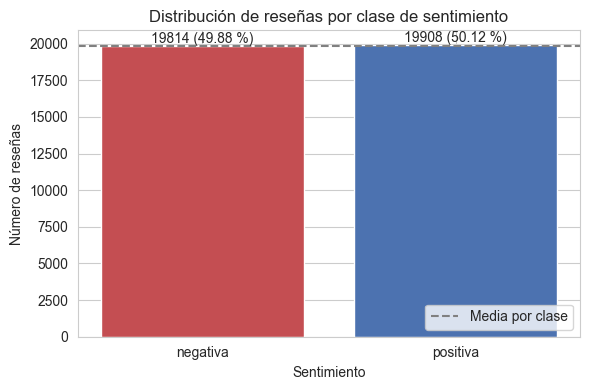

In [4]:
# Distribución de frecuencias absolutas y relativas por clase de sentimiento
class_counts = df_clean["label_name"].value_counts().reindex(CLASSES)
df_distribution = pd.DataFrame({
    "frecuencia_absoluta": class_counts,
    "frecuencia_relativa_%": (class_counts / class_counts.sum() * 100).round(2)
})
display(df_distribution)

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Clase mayoritaria: {class_counts.idxmax()} ({class_counts.max()})")
print(f"Clase minoritaria: {class_counts.idxmin()} ({class_counts.min()})")
print(f"Razón de desbalance (mayoritaria / minoritaria): {imbalance_ratio:.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(class_counts.index, class_counts.values, color=[CLASS_COLORS[c] for c in class_counts.index])
ax.axhline(class_counts.mean(), color="gray", linestyle="--", label="Media por clase")
for i, (count, pct) in enumerate(zip(class_counts, df_distribution["frecuencia_relativa_%"])):
    ax.text(i, count, f"{count} ({pct} %)", ha="center", va="bottom")
ax.set(xlabel="Sentimiento", ylabel="Número de reseñas", title="Distribución de reseñas por clase de sentimiento")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

#### 1.2.3. Distribución de la longitud de las reseñas por clase
Se calcula la longitud de cada reseña en caracteres y en palabras (sin contar las etiquetas HTML) y se reportan sus estadísticos descriptivos por clase, incluyendo los percentiles 90, 95 y 99, complementados con un histograma y un diagrama de caja por clase. El objetivo es dimensionar la longitud de las secuencias que deberá procesar la RNN y verificar que la longitud no varía sistemáticamente entre clases, lo que podría convertirse en un atajo para el modelo. Este análisis es descriptivo: la longitud máxima de secuencia (`MAX_LEN`) se fija en la sección 1.4.3 a partir del número de *tokens* de `Train` tras la limpieza.

Longitud en palabras:


,count,mean,std,min,50%,90%,95%,99%,max
negativa,19814.0,227.0,162.7,4.0,173.0,432.0,565.0,874.9,1491.0
positiva,19908.0,231.4,176.2,12.0,171.0,464.0,602.0,914.9,2459.0
total,39722.0,229.2,169.6,4.0,172.0,448.0,585.0,894.0,2459.0


Longitud en caracteres:


,count,mean,std,min,50%,90%,95%,99%,max
negativa,19814.0,1293.2,943.0,32.0,973.0,2479.7,3258.0,5041.7,8969.0
positiva,19908.0,1329.1,1033.0,65.0,973.0,2691.0,3498.6,5312.9,13704.0
total,39722.0,1311.2,989.3,32.0,973.0,2585.0,3390.0,5171.0,13704.0


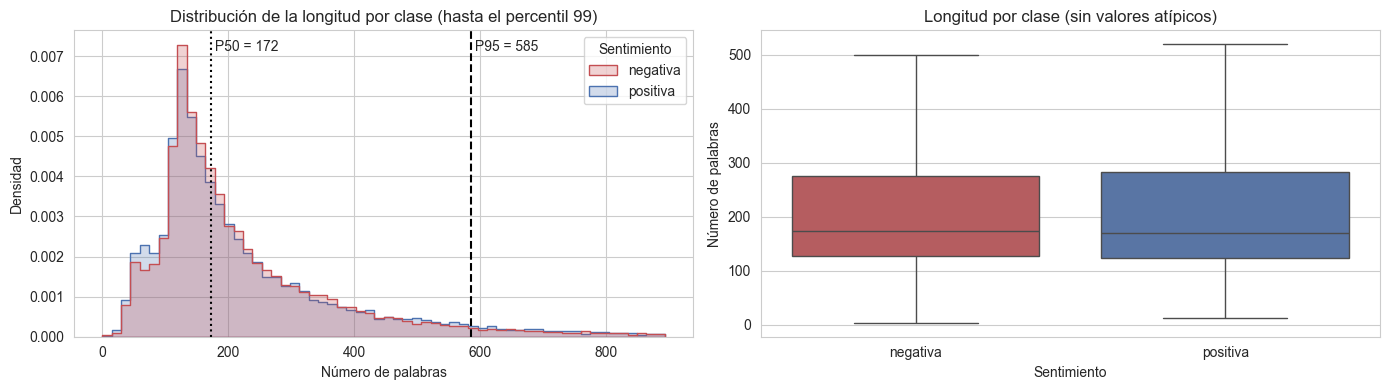

In [5]:
# Estadísticos descriptivos e histogramas de la longitud de las reseñas por clase
PERCENTILES = [0.5, 0.9, 0.95, 0.99]
df_clean["n_caracteres"] = df_clean["text"].str.len()
df_clean["n_palabras"] = df_clean["text"].map(normalize_for_dedup).str.split().str.len()

def length_summary(column: str) -> pd.DataFrame:
    by_class = df_clean.groupby("label_name")[column].describe(percentiles=PERCENTILES).reindex(CLASSES)
    overall = df_clean[column].describe(percentiles=PERCENTILES).to_frame("total").T
    return pd.concat([by_class, overall]).round(1)

print("Longitud en palabras:")
display(length_summary("n_palabras"))
print("Longitud en caracteres:")
display(length_summary("n_caracteres"))

# El histograma se limita al percentil 99 para que la cola larga no oculte la forma de la distribución
p99_words = df_clean["n_palabras"].quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df_clean, x="n_palabras", hue="label_name", hue_order=CLASSES, palette=CLASS_COLORS,
             bins=60, binrange=(0, p99_words), element="step", stat="density", common_norm=False, ax=axes[0])
sns.move_legend(axes[0], "upper right", title="Sentimiento")
for q, style in [(0.5, ":"), (0.95, "--")]:
    x = df_clean["n_palabras"].quantile(q)
    axes[0].axvline(x, color="black", linestyle=style)
    axes[0].text(x, axes[0].get_ylim()[1] * 0.97, f" P{int(q * 100)} = {x:.0f}", va="top")
axes[0].set(title="Distribución de la longitud por clase (hasta el percentil 99)",
            xlabel="Número de palabras", ylabel="Densidad")
sns.boxplot(data=df_clean, x="label_name", y="n_palabras", hue="label_name", order=CLASSES,
            palette=CLASS_COLORS, showfliers=False, legend=False, ax=axes[1])
axes[1].set(title="Longitud por clase (sin valores atípicos)", xlabel="Sentimiento", ylabel="Número de palabras")
plt.tight_layout()
plt.show()

#### 1.2.4. Inspección de ejemplos y ruido en el texto
Se muestran, con semilla fija para garantizar la reproducibilidad, dos reseñas de cada clase y se cuantifica, por clase, el porcentaje de reseñas que contienen elementos que deben tratarse en la limpieza: etiquetas HTML (p. ej. `<br />`), URLs, calificaciones numéricas explícitas (p. ej. `7/10`), contracciones (p. ej. *don't*), apóstrofos tipográficos (`’`) y caracteres no ASCII. Finalmente, se listan los caracteres no ASCII más frecuentes para definir su normalización.

In [6]:
# Visualización de reseñas de ejemplo por clase y cuantificación de ruido en el texto
N_EXAMPLES_PER_CLASS = 2
MAX_CHARS_SHOWN = 500

for cls_name in CLASSES:
    sample = df_clean[df_clean["label_name"] == cls_name].sample(N_EXAMPLES_PER_CLASS, random_state=RANDOM_STATE)
    for text in sample["text"]:
        print(f"[{cls_name}] {text[:MAX_CHARS_SHOWN]}{'...' if len(text) > MAX_CHARS_SHOWN else ''}\n")

NOISE_PATTERNS = {
    "Etiquetas HTML": r"<[^>]+>",
    "URLs": r"https?://\S+|www\.\S+",
    "Calificaciones numéricas (x/10)": r"\b\d+(?:\.\d+)?\s*/\s*10\b",
    "Contracciones (n't, 's, 're...)": r"[a-z]['’](?:t|s|re|ve|ll|d|m)\b",
    "Apóstrofos tipográficos (’ ‘ ` ´)": r"[’‘`´\x91\x92]",
    "Caracteres no ASCII": r"[^\x00-\x7f]",
}
df_noise = pd.DataFrame({
    name: df_clean.groupby("label_name")["text"]
                  .apply(lambda s: s.str.contains(pattern, case=False, regex=True).mean() * 100)
                  .reindex(CLASSES)
    for name, pattern in NOISE_PATTERNS.items()
}).T
df_noise["total"] = [df_clean["text"].str.contains(p, case=False, regex=True).mean() * 100
                     for p in NOISE_PATTERNS.values()]
print("Porcentaje de reseñas que contienen cada elemento:")
display(df_noise.round(2))

# Se muestra la representación del carácter y su código, ya que los caracteres de control de Windows-1252
# (p. ej. \x85, \x96, \x97) no son visibles e incluso pueden romper el formato de la tabla
non_ascii_counts = Counter(ch for text in df_clean["text"] for ch in text if ord(ch) > 127)
print("Caracteres no ASCII más frecuentes:")
display(pd.DataFrame([{
    "caracter": repr(ch),
    "código": f"U+{ord(ch):04X}",
    "nombre Unicode": unicodedata.name(ch, "control C1 (Windows-1252)"),
    "ocurrencias": count,
} for ch, count in non_ascii_counts.most_common(15)]))

[negativa] this fourth installment of the series is the last to get a theatrical release,though it feels like a direct to video movie.it's OK,i guess,but nothing special.the acting is the worst of seen in the series up to this point.and like the third movie,there isn't much in the way of imagination.also,the sentence "directed by Alan Smithee" is never a good thing.Smithee is the pseudonym directors use when they want nothing to do with the movie.anyway,its an acceptable movie in the Hellraiser series,but ...

[negativa] I guess I was prepared after all the years of hearing about it. First heard about it from Siskel and Ebert. When they said Divine ate excrement, I had to look it up. Then a friend told me about it in 1991. She said also that her parents saw it when it first came out and that her mom almost dumped her dad over it! So by the time I caught Pink Flamingos on Sundance today, I was prepared. For the most part.<br /><br />I still couldn't help but be surprised by the anal clo

label_name,negativa,positiva,total
Etiquetas HTML,59.64,57.25,58.44
URLs,0.32,0.43,0.38
Calificaciones numéricas (x/10),5.42,6.61,6.02
"Contracciones (n't, 's, 're...)",88.74,85.13,86.93
Apóstrofos tipográficos (’ ‘ ` ´),1.25,1.26,1.26
Caracteres no ASCII,10.17,8.52,9.35


Caracteres no ASCII más frecuentes:


,caracter,ocurrencias
0,é,2657
1,,1917
2,,1142
3,,476
4,´,339
5,’,201
6,á,178
7,è,125
8,ö,123
9,–,119


#### 1.2.5. Hallazgos del EDA

Todas las cifras corresponden al conjunto depurado ($39\,722$ reseñas únicas), salvo las de duplicados.

- **Registros nulos y duplicados:** el archivo contiene $40\,000$ reseñas sin valores nulos ni reseñas vacías. Se identificaron 277 copias exactas y una adicional que solo difiere en formato (278 en total), concentradas en `negativa` (205 frente a 73). Ninguna copia aparece con etiquetas contradictorias. Se conserva una sola reseña por grupo antes de cualquier análisis o partición, evitando que copias de una misma reseña queden simultáneamente en entrenamiento y prueba (*data leakage*).
- **Balance de clases:** el conjunto está prácticamente balanceado, con $19\,814$ reseñas negativas (49,88 %) y $19\,908$ positivas (50,12 %), y una razón de desbalance de 1,005. Por lo tanto, no es necesario ponderar la función de pérdida y la exactitud es una métrica informativa, aunque se reportan también *precision*, *recall* y *F1-score*, como exige el enunciado.
- **Longitud de las reseñas:** la distribución es asimétrica a la derecha, con una mediana de 172 palabras, una media de 229,2 (σ = 169,6) y una cola larga (percentil 95 = 585, percentil 99 = 894, máximo = $2\,459$). Las distribuciones de ambas clases son muy similares (medianas de 173 y 171 palabras; medias de 227,0 y 231,4), por lo que la longitud no constituye un atajo para distinguir el sentimiento. La cola larga obliga a truncar las secuencias: procesar las reseñas completas sería costoso para una RNN, cuyo cómputo es secuencial, y agravaría la dificultad de propagar el gradiente a lo largo de secuencias muy largas [6].
- **Ruido en el texto:** el 58,44 % de las reseñas contiene etiquetas HTML (principalmente `<br />`) y el 86,93 % contracciones (p. ej. *don't*, *isn't*). El 9,35 % contiene caracteres no ASCII, que corresponden a letras acentuadas en nombres propios (p. ej. `é`) y a caracteres de control de Windows-1252 (`\x96`, `\x85`, `\x97`) que en el texto original funcionan como guiones o puntos suspensivos; el 1,26 % usa apóstrofos tipográficos (`´`, `’`). Las URLs son marginales (0,38 %). El 6,02 % de las reseñas incluye calificaciones explícitas del tipo *x/10*, algo más frecuentes en las positivas (6,61 % frente a 5,42 %). La incidencia del ruido es similar en ambas clases, de modo que no introduce un sesgo evidente.
- **Implicaciones para el preprocesamiento:** (i) eliminar las etiquetas HTML y las URLs antes de tokenizar, para que `<br />` no se convierta en el *token* `br`; (ii) unificar los apóstrofos antes de expandir las contracciones, para preservar negaciones como *not*; (iii) reemplazar por un espacio, y no eliminar, los caracteres no ASCII residuales, para no unir las palabras que separan; (iv) conservar los números y el signo `/`, que forman las calificaciones explícitas; (v) fijar `MAX_LEN` a partir de la longitud en *tokens* de `Train` (sección 1.4.3); y (vi) entrenar sin pesos por clase.

### 1.3. Partición en Conjuntos de Entrenamiento, Validación y Prueba
El conjunto de datos depurado se divide de forma estratificada en los subconjuntos de entrenamiento (`Train`, 70 %), validación (`Val`, 15 %) y prueba (`Test`, 15 %), preservando la proporción de reseñas positivas y negativas. Se verifica que ninguna reseña (comparada tras la normalización de la sección 1.2.1) aparezca en más de una partición y que la proporción de cada clase se mantenga en las tres particiones. La partición se realiza **antes** de construir el vocabulario, fijar `MAX_LEN` y construir la matriz de *embeddings*, de modo que estos artefactos se ajusten exclusivamente con `Train`.

In [7]:
# Partición estratificada en conjuntos de entrenamiento, validación y prueba
VAL_SIZE = 0.15
TEST_SIZE = 0.15

df_train_val, df_test = train_test_split(
    df_clean, test_size=TEST_SIZE, stratify=df_clean["label"], random_state=RANDOM_STATE)
df_train, df_val = train_test_split(
    df_train_val, test_size=VAL_SIZE / (1 - TEST_SIZE), stratify=df_train_val["label"], random_state=RANDOM_STATE)
df_train, df_val, df_test = (df.reset_index(drop=True) for df in (df_train, df_val, df_test))
splits = {"Train": df_train, "Val": df_val, "Test": df_test}

# Verificación de ausencia de fuga de información entre particiones
normalized_texts = {name: set(df["text"].map(normalize_for_dedup)) for name, df in splits.items()}
assert normalized_texts["Train"].isdisjoint(normalized_texts["Val"])
assert normalized_texts["Train"].isdisjoint(normalized_texts["Test"])
assert normalized_texts["Val"].isdisjoint(normalized_texts["Test"])

# Verificación de la estratificación: proporción de cada clase en el total y en cada partición
split_counts = pd.DataFrame({name: df["label_name"].value_counts() for name, df in splits.items()}).reindex(CLASSES)
split_pct = pd.DataFrame({
    "Total_%": df_clean["label_name"].value_counts(normalize=True),
    **{f"{name}_%": df["label_name"].value_counts(normalize=True) for name, df in splits.items()}
}).reindex(CLASSES).mul(100).round(2)
display(pd.concat([split_counts, split_pct], axis=1))
print(" | ".join(f"{name}: {len(df)} ({len(df) / len(df_clean) * 100:.1f} %)" for name, df in splits.items()))

,Train,Val,Test,Total_%,Train_%,Val_%,Test_%
label_name,,,,,,,
negativa,13869,2973,2972,49.88,49.88,49.89,49.87
positiva,13935,2986,2987,50.12,50.12,50.11,50.13


Train: 27804 (70.0 %) | Val: 5959 (15.0 %) | Test: 5959 (15.0 %)


### 1.4. Pipeline de Preprocesamiento: Limpieza, Tokenización, Vocabulario y *Embeddings*
Se construye el *pipeline* que transforma cada reseña en una secuencia de índices enteros apta para la capa de *embedding* de la red recurrente. El orden de los pasos no es arbitrario: cada uno depende de que el anterior haya dejado el texto en la forma esperada.

| # | Paso | Ajustado con | Razón de su posición |
| :-: | :--- | :--- | :--- |
| 1 | Eliminación de etiquetas HTML y URLs | — | Debe ir primero: de lo contrario el tokenizador convierte `<br />` en el *token* `br` y fragmenta las URLs. |
| 2 | Normalización de caracteres (apóstrofos tipográficos → `'`, acentos → ASCII, demás caracteres no ASCII → espacio) | — | Antes de expandir contracciones: *don’t* con apóstrofo tipográfico no coincidiría con los patrones de contracción. Los caracteres no ASCII se reemplazan por espacio y no se eliminan, porque varios (p. ej. guiones de Windows-1252) separan palabras. |
| 3 | Conversión a minúsculas | — | Antes de expandir contracciones (patrones en minúsculas) y porque GloVe 6B es un vocabulario sin mayúsculas [4]. |
| 4 | Expansión de contracciones (*don't* → *do not*) | — | Antes de tokenizar: el tokenizador separaría *don't* en `don` y `t`, y la negación `not` desaparecería. |
| 5 | Tokenización (`[a-z0-9]+` y los signos `!`, `?`, `/`) | — | Último paso sin estado: descarta la puntuación restante y conserva números y calificaciones como `7 / 10`. |
| 6 | Construcción del vocabulario (`MIN_FREQ`) | `Train` | Requiere el texto tokenizado y debe ajustarse solo con `Train`. |
| 7 | Codificación, truncado y relleno (`MAX_LEN`) | `Train` | Requiere el vocabulario; `MAX_LEN` se fija con la longitud en *tokens* de `Train`. |
| 8 | Matriz de *embeddings* preentrenados | `Train` | Requiere el vocabulario: cada fila corresponde a un índice. |
| 9 | `Dataset` y `DataLoader` | — | Empaqueta las secuencias, longitudes y etiquetas para el entrenamiento. |

Deliberadamente **no** se aplican tres pasos habituales en representaciones de bolsa de palabras:
- **Eliminación de palabras vacías (*stopwords*):** la lista en inglés de `nltk` incluye *not*, *no*, *nor*, *don't* o *isn't*; eliminarlas convertiría *\"not good\"* en *\"good\"* e invertiría la polaridad. La RNN aprende por sí misma a restar peso a las palabras de función a partir de su contexto.
- ***Stemming* o lematización:** produce raíces (p. ej. `movi`, `act`) que no existen en el vocabulario de GloVe, lo que reduciría la cobertura de los *embeddings* preentrenados.
- **Eliminación de números:** las calificaciones explícitas (p. ej. *\"3/10\"*, *\"10/10\"*) son una señal directa del sentimiento.

#### 1.4.1. Limpieza, normalización y tokenización del texto
Se implementan los pasos 1 a 5 como funciones independientes y se muestra su efecto paso a paso sobre una reseña de `Train` que contiene etiquetas HTML y contracciones, junto con una tabla que compara el texto original con el procesado. Como estos pasos no aprenden nada de los datos, se aplican por igual a las tres particiones. Finalmente, se verifica cuantitativamente el efecto del orden: se cuentan en `Train` los *tokens* espurios (`br`, `t`, `s`, `don`, `isn`, `didn`) y las ocurrencias de `not` que produce un tokenizador ingenuo (minúsculas y separación por caracteres alfanuméricos, sin limpieza previa) frente al *pipeline* propuesto.

In [8]:
# Definición de las funciones de limpieza, normalización y tokenización
HTML_TAG_RE = re.compile(r"<[^>]+>")
URL_RE = re.compile(r"https?://\S+|www\.\S+")
APOSTROPHE_RE = re.compile(r"[’‘`´\x91\x92]")
NON_ASCII_RE = re.compile(r"[^\x00-\x7f]")
# Contracciones irregulares y formas con 's que equivalen a "is"; el resto de 's se trata como posesivo
SPECIAL_CONTRACTIONS = {
    r"\bwon't\b": "will not", r"\bcan't\b": "can not", r"\bshan't\b": "shall not",
    r"\bain't\b": "is not", r"\blet's\b": "let us",
    r"\b(it|that|there|here|what|who|where|he|she)'s\b": r"\1 is",
}
SUFFIX_CONTRACTIONS = {
    r"n't\b": " not", r"'re\b": " are", r"'ve\b": " have", r"'ll\b": " will",
    r"'d\b": " would", r"'m\b": " am", r"'s\b": "",
}
TOKEN_PATTERN = r"[a-z0-9]+|[!?/]"
tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def remove_html_and_urls(text: str) -> str:
    return URL_RE.sub(" ", HTML_TAG_RE.sub(" ", text))

def normalize_characters(text: str) -> str:
    text = APOSTROPHE_RE.sub("'", text)
    # NFKD descompone los caracteres acentuados (é -> e + tilde) y se descartan las marcas diacríticas
    text = "".join(ch for ch in unicodedata.normalize("NFKD", text) if not unicodedata.combining(ch))
    # El resto de caracteres no ASCII (p. ej. guiones y puntos suspensivos de Windows-1252) se reemplaza
    # por un espacio para no unir las palabras que separan
    return NON_ASCII_RE.sub(" ", text)

def expand_contractions(text: str) -> str:
    for pattern, replacement in {**SPECIAL_CONTRACTIONS, **SUFFIX_CONTRACTIONS}.items():
        text = re.sub(pattern, replacement, text)
    return text

def clean_text(text: str) -> str:
    text = remove_html_and_urls(text)
    text = normalize_characters(text)
    text = text.lower()
    return expand_contractions(text)

def tokenize(text: str) -> list:
    return tokenizer.tokenize(clean_text(text))

# Efecto paso a paso sobre una reseña de Train con etiquetas HTML y contracciones
has_noise = df_train["text"].str.contains("<br") & df_train["text"].str.contains(r"n't\b")
sample_text = df_train.loc[has_noise, "text"].iloc[0]
steps = [("Texto original", sample_text)]
steps.append(("1. Sin HTML ni URLs", remove_html_and_urls(steps[-1][1])))
steps.append(("2. Caracteres normalizados", normalize_characters(steps[-1][1])))
steps.append(("3. Minúsculas", steps[-1][1].lower()))
steps.append(("4. Contracciones expandidas", expand_contractions(steps[-1][1])))
steps.append(("5. Tokens", " | ".join(tokenizer.tokenize(steps[-1][1]))))
for name, text in steps:
    print(f"{name}:\n{text[:MAX_CHARS_SHOWN]}{'...' if len(text) > MAX_CHARS_SHOWN else ''}\n")

Texto original:
I must have seen this movie about four or five times already, and it gets better with each viewing. Suffice it to say: This is the best film I've ever seen. And I think I've seen a lot.<br /><br />But I've always wondered why this film got so shunned in some reviews or ratings. For example, take the IMDb Top 250. Why does it rank only at #216 (as of today)? Surely, the answer's not in the film itself (because that is nothing but flawless), but in its reception. The film caused controversy in its...

1. Sin HTML ni URLs:
I must have seen this movie about four or five times already, and it gets better with each viewing. Suffice it to say: This is the best film I've ever seen. And I think I've seen a lot.  But I've always wondered why this film got so shunned in some reviews or ratings. For example, take the IMDb Top 250. Why does it rank only at #216 (as of today)? Surely, the answer's not in the film itself (because that is nothing but flawless), but in its reception. Th

In [9]:
# Aplicación del pipeline a las tres particiones y comparación del texto original con el procesado
for df in splits.values():
    df["tokens"] = df["text"].map(tokenize)

processed_sample = " ".join(tokenize(sample_text))
display(pd.DataFrame({
    "etapa": ["Texto original", "Texto procesado"],
    "caracteres": [len(sample_text), len(processed_sample)],
    "palabras / tokens": [len(sample_text.split()), len(processed_sample.split())],
    "texto": [sample_text[:300], processed_sample[:300]],
}))

# Verificación del orden: tokens espurios y negaciones con un tokenizador ingenuo frente al pipeline propuesto
naive_tokenizer = RegexpTokenizer(r"[a-z0-9]+")
naive_counts = Counter(t for text in df_train["text"] for t in naive_tokenizer.tokenize(text.lower()))
pipeline_counts = Counter(t for tokens in df_train["tokens"] for t in tokens)
check_tokens = ["br", "t", "s", "don", "isn", "didn", "not"]
display(pd.DataFrame({
    "tokenizador ingenuo": [naive_counts[t] for t in check_tokens],
    "pipeline propuesto": [pipeline_counts[t] for t in check_tokens],
}, index=pd.Index(check_tokens, name="token")))

n_empty_tokens = sum(int(df["tokens"].map(len).eq(0).sum()) for df in splits.values())
print(f"Reseñas que quedan vacías tras la limpieza: {n_empty_tokens}")

,etapa,caracteres,palabras / tokens,texto
0,Texto original,1717,296,I must have seen this movie about four or five...
1,Texto procesado,1647,313,i must have seen this movie about four or five...


,tokenizador ingenuo,pipeline propuesto
token,,
br,112258,3
t,38403,842
s,70274,961
don,9826,347
isn,3575,0
didn,4838,2
not,33958,71506


Reseñas que quedan vacías tras la limpieza: 0


#### 1.4.2. Análisis del vocabulario y construcción del vocabulario sobre `Train`
A partir de los *tokens* de `Train` se analiza el vocabulario: tamaño, proporción de palabras que aparecen una sola vez (*hapax legomena*) y cobertura acumulada de las ocurrencias en función del número de palabras más frecuentes (ley de Zipf). Para justificar cuantitativamente las decisiones del *pipeline*, se compara el tamaño del vocabulario sin limpieza, con la limpieza completa y con el filtro de frecuencia mínima `MIN_FREQ`. Como verificación cualitativa, se identifican los términos con mayor diferencia de peso TF-IDF medio entre clases, sin eliminar palabras vacías.

Con base en este análisis se construye el vocabulario con las palabras de `Train` que aparecen al menos `MIN_FREQ` veces. Se reservan los índices especiales `<pad>` = 0 (relleno) y `<unk>` = 1 (palabras fuera del vocabulario) y se reporta la tasa de palabras fuera del vocabulario (OOV) en cada partición.

,términos
Sin limpieza (minúsculas y alfanuméricos),79889
Con limpieza completa,79610
Con limpieza y MIN_FREQ = 5,30730


findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['DejaVu Sans Display'] not found. Falling back to DejaVu Sans.


Hapax legomena: 29822 (37.5 % del vocabulario, 0.45 % de las ocurrencias)
Cobertura de las ocurrencias de Train con MIN_FREQ = 5: 98.77 %


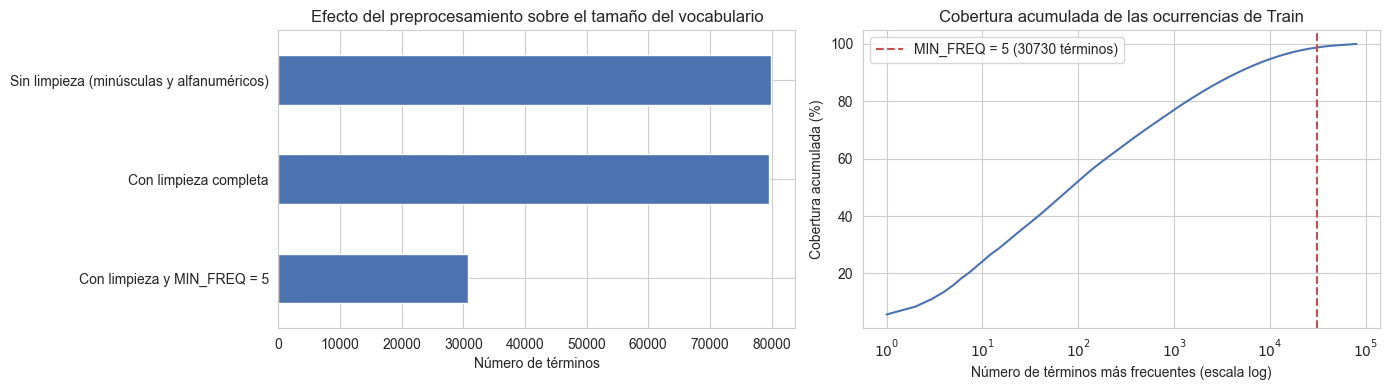

In [10]:
# Tamaño del vocabulario por etapa de preprocesamiento, hapax legomena y curva de cobertura acumulada
MIN_FREQ = 5

token_counts = pipeline_counts  # frecuencias de los tokens de Train calculadas en la sección 1.4.1
total_occurrences = sum(token_counts.values())
freqs = np.array(sorted(token_counts.values(), reverse=True))
cumulative_coverage = np.cumsum(freqs) / total_occurrences * 100
n_frequent = int((freqs >= MIN_FREQ).sum())

vocab_sizes = pd.Series({
    "Sin limpieza (minúsculas y alfanuméricos)": len(naive_counts),
    "Con limpieza completa": len(token_counts),
    f"Con limpieza y MIN_FREQ = {MIN_FREQ}": n_frequent,
}, name="términos")
display(vocab_sizes.to_frame())
n_hapax = int((freqs == 1).sum())
print(f"Hapax legomena: {n_hapax} ({n_hapax / len(freqs) * 100:.1f} % del vocabulario, "
      f"{n_hapax / total_occurrences * 100:.2f} % de las ocurrencias)")
print(f"Cobertura de las ocurrencias de Train con MIN_FREQ = {MIN_FREQ}: {cumulative_coverage[n_frequent - 1]:.2f} %")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
vocab_sizes.plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set(title="Efecto del preprocesamiento sobre el tamaño del vocabulario", xlabel="Número de términos")
axes[0].invert_yaxis()
axes[1].plot(np.arange(1, len(freqs) + 1), cumulative_coverage, color="#4C72B0")
axes[1].axvline(n_frequent, color="#C44E52", linestyle="--", label=f"MIN_FREQ = {MIN_FREQ} ({n_frequent} términos)")
axes[1].set(xscale="log", title="Cobertura acumulada de las ocurrencias de Train",
            xlabel="Número de términos más frecuentes (escala log)", ylabel="Cobertura acumulada (%)")
axes[1].legend()
plt.tight_layout()
plt.show()

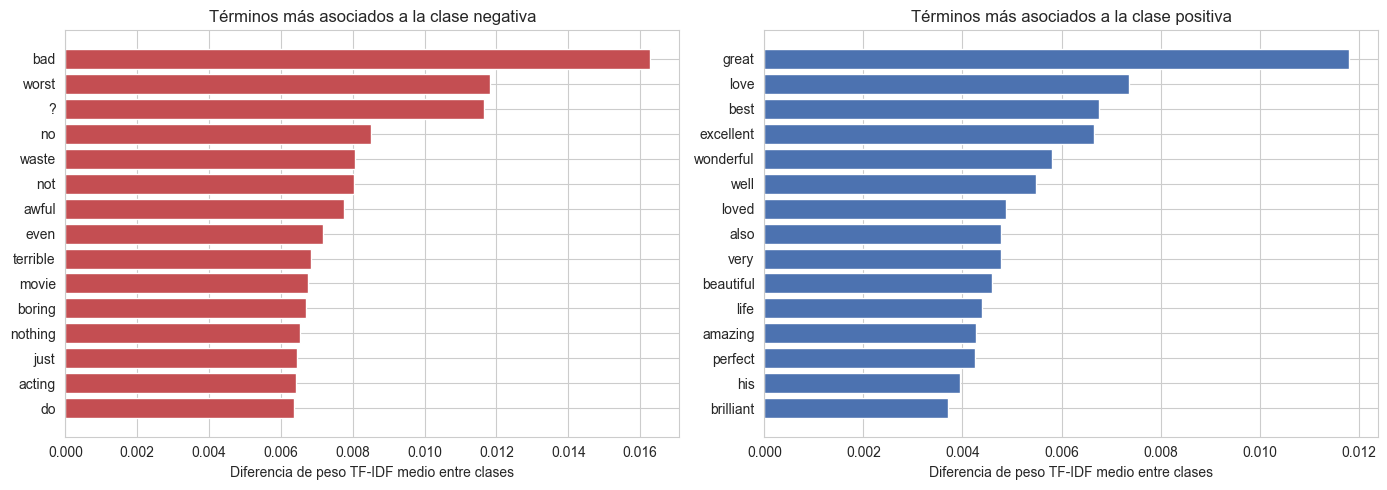

In [11]:
# Términos con mayor diferencia de peso TF-IDF medio entre clases (verificación cualitativa sobre Train)
N_TOP_TERMS = 15
tfidf = TfidfVectorizer(analyzer=lambda tokens: tokens, min_df=MIN_FREQ, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(df_train["tokens"])
feature_names = tfidf.get_feature_names_out()
is_positive = df_train["label"].to_numpy() == 1
mean_diff = (np.asarray(X_train_tfidf[is_positive].mean(axis=0)).ravel()
             - np.asarray(X_train_tfidf[~is_positive].mean(axis=0)).ravel())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cls_name, idx in [(axes[0], "negativa", np.argsort(mean_diff)[:N_TOP_TERMS]),
                          (axes[1], "positiva", np.argsort(mean_diff)[::-1][:N_TOP_TERMS])]:
    ax.barh(feature_names[idx][::-1], np.abs(mean_diff[idx])[::-1], color=CLASS_COLORS[cls_name])
    ax.set(title=f"Términos más asociados a la clase {cls_name}",
           xlabel="Diferencia de peso TF-IDF medio entre clases")
plt.tight_layout()
plt.show()

In [12]:
# Construcción del vocabulario sobre Train y tasa de palabras fuera del vocabulario (OOV)
PAD_TOKEN, UNK_TOKEN = "<pad>", "<unk>"
PAD_IDX, UNK_IDX = 0, 1

itos = [PAD_TOKEN, UNK_TOKEN] + [token for token, count in token_counts.most_common() if count >= MIN_FREQ]
stoi = {token: idx for idx, token in enumerate(itos)}
VOCAB_SIZE = len(itos)
print(f"Tamaño del vocabulario (incluye {PAD_TOKEN} y {UNK_TOKEN}): {VOCAB_SIZE}")

oov_rates = {}
for name, df in splits.items():
    n_tokens = int(df["tokens"].map(len).sum())
    n_oov = sum(token not in stoi for tokens in df["tokens"] for token in tokens)
    oov_rates[name] = {"tokens": n_tokens, "tokens OOV": n_oov, "tasa_OOV_%": round(n_oov / n_tokens * 100, 2)}
display(pd.DataFrame(oov_rates).T)

Tamaño del vocabulario (incluye <pad> y <unk>): 30732


,tokens,tokens OOV,tasa_OOV_%
Train,6599945.0,81130.0,1.23
Val,1407402.0,22214.0,1.58
Test,1385229.0,21196.0,1.53


#### 1.4.3. Codificación numérica, truncado y relleno de secuencias
Se analiza la longitud en *tokens* de las reseñas de `Train` y, para varios valores candidatos de `MAX_LEN`, el porcentaje de reseñas que se truncarían y el porcentaje de *tokens* que se conservarían. Con base en ello se fija `MAX_LEN`, buscando un equilibrio entre la información conservada y el costo computacional, que en una RNN crece linealmente con la longitud de la secuencia.

Cada reseña se convierte en una secuencia de índices del vocabulario (`<unk>` para las palabras fuera de él). Las reseñas más largas que `MAX_LEN` se truncan conservando los **últimos** `MAX_LEN` *tokens*, ya que la conclusión de una reseña suele contener el juicio global del autor y queda más cerca del estado oculto final de la red; la estrategia alternativa (conservar el inicio) puede compararse en los experimentos de la sección 2.4. Las secuencias más cortas se rellenan con `<pad>` **al final**, y se conserva la longitud real de cada una para empaquetarlas (`pack_padded_sequence`), de modo que la red no procese los *tokens* de relleno.

In [13]:
# Análisis de la longitud en tokens de Train para definir MAX_LEN
MAX_LEN_CANDIDATES = [100, 200, 300, 400, 500, 600, 800]
train_token_lengths = df_train["tokens"].map(len)
display(train_token_lengths.describe(percentiles=PERCENTILES).round(1).to_frame("tokens por reseña (Train)").T)
display(pd.DataFrame([{
    "MAX_LEN": max_len,
    "reseñas truncadas_%": round((train_token_lengths > max_len).mean() * 100, 2),
    "tokens conservados_%": round(train_token_lengths.clip(upper=max_len).sum() / train_token_lengths.sum() * 100, 2),
} for max_len in MAX_LEN_CANDIDATES]).set_index("MAX_LEN"))

,count,mean,std,min,50%,90%,95%,99%,max
tokens por reseña (Train),27804.0,237.4,175.1,8.0,179.0,464.0,605.0,928.0,2281.0


,reseñas truncadas_%,tokens conservados_%
MAX_LEN,,
100,88.29,40.63
200,42.73,67.79
300,23.32,81.13
400,13.61,88.71
500,8.31,93.24
600,5.10,96.03
800,1.99,98.83


In [14]:
# Codificación de reseñas en índices, truncado/relleno a MAX_LEN y registro de longitudes reales
MAX_LEN = 400
TRUNCATION = "tail"  # "tail" conserva los últimos MAX_LEN tokens; "head" conserva los primeros

def encode(tokens: list, max_len: int = MAX_LEN, truncation: str = TRUNCATION) -> tuple:
    ids = [stoi.get(token, UNK_IDX) for token in tokens] or [UNK_IDX]
    ids = ids[-max_len:] if truncation == "tail" else ids[:max_len]
    return ids + [PAD_IDX] * (max_len - len(ids)), len(ids)

encoded = {}
for name, df in splits.items():
    sequences, lengths = zip(*df["tokens"].map(encode))
    encoded[name] = {"sequences": np.array(sequences, dtype=np.int64),
                     "lengths": np.array(lengths, dtype=np.int64),
                     "labels": df["label"].to_numpy(dtype=np.float32)}
    print(f"{name}: secuencias {encoded[name]['sequences'].shape} | "
          f"truncadas: {(df['tokens'].map(len) > MAX_LEN).mean() * 100:.2f} %")

# Verificación: reconstrucción del texto a partir de los índices de una reseña de Train
example_ids, example_len = encoded["Train"]["sequences"][0], encoded["Train"]["lengths"][0]
print(f"\nTokens originales (primeros 25): {df_train['tokens'][0][:25]}")
print(f"Índices (primeros 25):           {example_ids[:25].tolist()}")
print(f"Reconstrucción (primeros 25):    {[itos[i] for i in example_ids[:25]]}")
print(f"Longitud real: {example_len} | Relleno: {MAX_LEN - example_len} posiciones con índice {PAD_IDX}")

Train: secuencias (27804, 400) | truncadas: 13.61 %
Val: secuencias (5959, 400) | truncadas: 13.91 %
Test: secuencias (5959, 400) | truncadas: 12.89 %

Tokens originales (primeros 25): ['this', 'is', 'the', 'worst', 'film', 'i', 'have', 'ever', 'seen', 'and', 'what', 'disappoints', 'me', 'the', 'most', 'is', 'that', 'this', 'is', 'yash', 'raj', 'film', 'so', 'at', 'first']
Índices (primeros 25):           [11, 6, 2, 240, 20, 10, 24, 125, 111, 3, 49, 12002, 74, 2, 92, 6, 12, 11, 6, 15057, 6523, 20, 37, 30, 91]
Reconstrucción (primeros 25):    ['this', 'is', 'the', 'worst', 'film', 'i', 'have', 'ever', 'seen', 'and', 'what', 'disappoints', 'me', 'the', 'most', 'is', 'that', 'this', 'is', 'yash', 'raj', 'film', 'so', 'at', 'first']
Longitud real: 148 | Relleno: 252 posiciones con índice 0


#### 1.4.4. Construcción de la matriz de *embeddings* preentrenados
Se emplean los vectores GloVe 6B de dimensión 100 [4], entrenados sobre Wikipedia y Gigaword con un vocabulario de $400\,000$ palabras en minúsculas, coherente con la normalización aplicada en la sección 1.4.1. Si el archivo no se encuentra en `data/glove/`, se descarga del repositorio oficial de Stanford NLP en Hugging Face (≈ 822 MB) y se extrae únicamente el archivo de 100 dimensiones.

Se construye la matriz de *embeddings* de dimensión `VOCAB_SIZE × EMBED_DIM` alineada con el vocabulario de `Train`: las palabras con vector preentrenado lo copian, las palabras sin vector (y `<unk>`) se inicializan aleatoriamente con la misma escala que los vectores GloVe y el vector de `<pad>` se fija en ceros. Se reporta la cobertura del vocabulario (porcentaje de términos y de ocurrencias de `Train` con vector preentrenado), las palabras frecuentes sin vector y, como verificación cualitativa, los vecinos más cercanos por similitud coseno de algunas palabras con carga de sentimiento. La cobertura determina si conviene congelar o ajustar (*fine-tuning*) la capa de *embedding*.

In [15]:
# Descarga (si es necesario) y carga de los vectores GloVe
EMBED_DIM = 100
GLOVE_DIR = Path("./data/glove")
GLOVE_PATH = GLOVE_DIR / f"glove.6B.{EMBED_DIM}d.txt"
GLOVE_URL = "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip"

if not GLOVE_PATH.exists():
    GLOVE_DIR.mkdir(parents=True, exist_ok=True)
    zip_path = GLOVE_DIR / "glove.6B.zip"
    print(f"Descargando {GLOVE_URL} (≈ 822 MB)...")
    urllib.request.urlretrieve(GLOVE_URL, zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extract(GLOVE_PATH.name, GLOVE_DIR)
    zip_path.unlink()

# Solo se cargan los vectores de las palabras del vocabulario de Train
glove_vectors = {}
with open(GLOVE_PATH, encoding="utf-8") as f:
    for line in f:
        word, values = line.split(" ", 1)
        if word in stoi:
            glove_vectors[word] = np.asarray(values.split(), dtype=np.float32)
print(f"Vectores GloVe encontrados para el vocabulario: {len(glove_vectors)} de {VOCAB_SIZE - 2}")

Descargando https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip (≈ 822 MB)...
Vectores GloVe encontrados para el vocabulario: 30179 de 30730


In [16]:
# Construcción de la matriz de embeddings y cobertura del vocabulario
rng = np.random.default_rng(RANDOM_STATE)
glove_std = np.stack(list(glove_vectors.values())).std()
embedding_matrix = rng.normal(0, glove_std, size=(VOCAB_SIZE, EMBED_DIM)).astype(np.float32)
embedding_matrix[PAD_IDX] = 0.0
for word, vector in glove_vectors.items():
    embedding_matrix[stoi[word]] = vector
EMBEDDING_MATRIX = torch.from_numpy(embedding_matrix)

vocab_words = itos[2:]
covered_occurrences = sum(token_counts[w] for w in vocab_words if w in glove_vectors)
vocab_occurrences = sum(token_counts[w] for w in vocab_words)
print(f"Matriz de embeddings: {tuple(EMBEDDING_MATRIX.shape)}")
print(f"Cobertura de términos del vocabulario: {len(glove_vectors) / len(vocab_words) * 100:.2f} %")
print(f"Cobertura de ocurrencias en Train: {covered_occurrences / vocab_occurrences * 100:.2f} %")

missing_words = [(w, token_counts[w]) for w in vocab_words if w not in glove_vectors]
print("\nPalabras más frecuentes sin vector preentrenado:")
display(pd.DataFrame(missing_words[:15], columns=["palabra", "ocurrencias en Train"]))

# Verificación cualitativa: vecinos más cercanos (similitud coseno) dentro del vocabulario
QUERY_WORDS = ["good", "bad", "not", "boring", "masterpiece"]
normalized = embedding_matrix / np.maximum(np.linalg.norm(embedding_matrix, axis=1, keepdims=True), 1e-8)
neighbors = {}
for word in QUERY_WORDS:
    similarities = normalized @ normalized[stoi[word]]
    nearest = [i for i in np.argsort(similarities)[::-1] if i != stoi[word]][:6]
    neighbors[word] = [f"{itos[i]} ({similarities[i]:.2f})" for i in nearest]
display(pd.DataFrame(neighbors))

Matriz de embeddings: (30732, 100)
Cobertura de términos del vocabulario: 98.21 %
Cobertura de ocurrencias en Train: 99.93 %

Palabras más frecuentes sin vector preentrenado:


,palabra,ocurrencias en Train
0,imho,47
1,hynkel,42
2,gypo,36
3,feinstone,35
4,trivialboring,26
5,cheezy,24
6,sheeta,24
7,afroreggae,24
8,trelkovsky,23
9,raisuli,22


,good,bad,not,boring,masterpiece
0,better (0.89),worse (0.79),be (0.93),tedious (0.72),masterpieces (0.72)
1,sure (0.83),good (0.77),would (0.93),dull (0.70),masterwork (0.70)
2,really (0.83),things (0.77),could (0.92),bored (0.69),cinematic (0.64)
3,kind (0.83),too (0.76),should (0.91),funny (0.68),anthology (0.60)
4,very (0.83),thing (0.76),they (0.91),stupid (0.67),epic (0.60)
5,we (0.82),lot (0.74),did (0.91),downright (0.67),monumental (0.60)


#### 1.4.5. Definición de la clase `Dataset` y generadores `DataLoader`
La clase `IMDbReviewsDataset` devuelve, para cada reseña, la secuencia de índices de longitud `MAX_LEN`, su longitud real y su etiqueta (como `float`, el formato que espera `BCEWithLogitsLoss`). Se crean los `DataLoaders` de entrenamiento (con barajado reproducible), validación y prueba, y se verifica un lote de ejemplo: dimensiones de los tensores, rango de longitudes, que todas las posiciones posteriores a la longitud real correspondan a `<pad>` y la reconstrucción del texto a partir de los índices.

In [17]:
# Definición de la clase Dataset, generadores DataLoader y verificación de un lote de ejemplo
BATCH_SIZE = 64
# En Jupyter sobre macOS/Windows, num_workers > 0 falla con clases definidas en el notebook
NUM_WORKERS = 0

class IMDbReviewsDataset(Dataset):
    def __init__(self, sequences: np.ndarray, lengths: np.ndarray, labels: np.ndarray):
        self.sequences = torch.from_numpy(sequences)
        self.lengths = torch.from_numpy(lengths)
        self.labels = torch.from_numpy(labels)

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx: int) -> tuple:
        return self.sequences[idx], self.lengths[idx], self.labels[idx]

datasets = {name: IMDbReviewsDataset(**arrays) for name, arrays in encoded.items()}
train_loader = DataLoader(datasets["Train"], batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                          generator=torch.Generator().manual_seed(RANDOM_STATE))
val_loader = DataLoader(datasets["Val"], batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(datasets["Test"], batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
print(" | ".join(f"{name}: {len(ds)} reseñas, {len(loader)} lotes"
                 for (name, ds), loader in zip(datasets.items(), [train_loader, val_loader, test_loader])))

# Verificación de un lote de ejemplo
batch_sequences, batch_lengths, batch_labels = next(iter(train_loader))
print(f"\nSecuencias: {tuple(batch_sequences.shape)} {batch_sequences.dtype} | "
      f"Longitudes: {tuple(batch_lengths.shape)} (mín. {batch_lengths.min().item()}, máx. {batch_lengths.max().item()}) | "
      f"Etiquetas: {tuple(batch_labels.shape)} {batch_labels.dtype}")
positions = torch.arange(MAX_LEN).unsqueeze(0)
assert (batch_sequences[positions >= batch_lengths.unsqueeze(1)] == PAD_IDX).all()
assert (batch_sequences[positions < batch_lengths.unsqueeze(1)] != PAD_IDX).all()
print(f"Proporción de positivas en el lote: {batch_labels.mean().item():.2f}")
first_ids = batch_sequences[0, :batch_lengths[0]].tolist()
print(f"\nReseña reconstruida ({LABEL_NAMES[int(batch_labels[0])]}): {' '.join(itos[i] for i in first_ids)[:MAX_CHARS_SHOWN]}...")

Train: 27804 reseñas, 435 lotes | Val: 5959 reseñas, 94 lotes | Test: 5959 reseñas, 94 lotes

Secuencias: (64, 400) torch.int64 | Longitudes: (64,) (mín. 62, máx. 400) | Etiquetas: (64,) torch.float32
Proporción de positivas en el lote: 0.55

Reseña reconstruida (negativa): i have recently found this film on one of my husband vhs tapes the blank variety which he uses to record stuff from the telly the film looks as if it was last shown in the eighties and i do not remember having seen it since it has not to my knowledge been released on dvd or vhs although i shall browse around for a copy the film tells the story of three young people two girls one on the edge of puberty and the other much younger and a young boy who go to live with their mother brother and his you...


#### 1.4.6. Hallazgos del Preprocesamiento

- **Orden de los pasos:** frente a un tokenizador ingenuo (minúsculas y separación por caracteres alfanuméricos), el *pipeline* propuesto reduce en `Train` los *tokens* espurios `br` de $112\,258$ a 3, `isn` de $3\,575$ a 0 y `didn` de $4\,838$ a 2, y duplica las ocurrencias de `not` ($33\,958$ → $71\,506$) al recuperar las negaciones contenidas en las contracciones. Los *tokens* `t` y `s` residuales (842 y 961) provienen de abreviaturas (*u.s.*), frases en francés (*je t'ai*) y palabras censuradas (*sh\*t*), y no de errores en el orden de los pasos. Ninguna reseña queda vacía tras la limpieza.
- **Vocabulario:** la limpieza reduce levemente el vocabulario de `Train` ($79\,889$ → $79\,610$ términos); la reducción principal proviene del filtro `MIN_FREQ = 5`, que lo deja en $30\,730$ términos ($30\,732$ con `<pad>` y `<unk>`) y aun así cubre el 98,77 % de las ocurrencias. El 37,5 % de los términos aparece una sola vez, pero representa apenas el 0,45 % de las ocurrencias. La tasa de palabras fuera del vocabulario es baja y similar entre particiones (1,23 % en `Train`, 1,58 % en `Val` y 1,53 % en `Test`).
- **Términos discriminativos:** los términos más asociados a la clase negativa incluyen *bad*, *worst*, *waste*, *awful* y *boring*, y a la positiva *great*, *love*, *best*, *excellent* y *wonderful*. Entre los negativos aparecen también `not`, `no` y `?`, lo que confirma empíricamente la decisión de no eliminar las palabras vacías ni los signos `!` y `?`.
- **Longitud de secuencia:** en `Train`, la longitud en *tokens* tiene una mediana de 179, un percentil 95 de 605 y un máximo de $2\,281$. Con `MAX_LEN = 400` se trunca el 13,61 % de las reseñas y se conserva el 88,71 % de los *tokens*; aumentarlo a 600 conservaría el 96,03 % a cambio de secuencias un 50 % más largas, con un costo de cómputo que en una RNN crece linealmente con la longitud. La proporción de reseñas truncadas es similar en `Val` (13,91 %) y `Test` (12,89 %).
- ***Embeddings* preentrenados:** el 98,21 % de los términos del vocabulario ($30\,179$ de $30\,730$) tiene vector GloVe, lo que equivale al 99,93 % de las ocurrencias de `Train`. Las palabras sin vector son poco frecuentes (≤ 47 ocurrencias) y corresponden a nombres propios (*hynkel*, *trelkovsky*), escritura informal (*cheezy*, *imho*) o palabras unidas en el texto original (*trivialboring*). Los vecinos más cercanos confirman que los vectores capturan relaciones semánticas (*masterpiece* → *masterwork*, *boring* → *tedious*, *dull*), pero también una limitación conocida de los *embeddings* distribucionales para el análisis de sentimiento: palabras de polaridad opuesta que aparecen en contextos similares quedan próximas (similitud coseno de 0,77 entre *bad* y *good*), y el vector de *not* se agrupa con verbos auxiliares (*be*, *would*), sin codificar la negación. Esto motiva comparar *embeddings* congelados frente a ajustados (*fine-tuning*) en la sección 2.4, y justifica el uso de una red recurrente que interprete cada palabra según su contexto.
- **Generadores de datos:** los `DataLoaders` producen 435 lotes de entrenamiento y 94 de validación y de prueba, con tamaño de lote 64. Las verificaciones confirman que todas las posiciones posteriores a la longitud real de cada secuencia corresponden a `<pad>` y que la reseña se reconstruye correctamente a partir de los índices.

---
## 2. Desarrollo de la Arquitectura de Red Neuronal Recurrente (RNN)
En esta sección se formula e implementa la arquitectura de red neuronal recurrente orientada a la clasificación binaria de las reseñas, compuesta por una capa de *embedding*, una o varias capas recurrentes (LSTM [1] o GRU [2]) y una capa densa de salida con activación sigmoide.

### 2.1. Definición de la Arquitectura del Modelo
Se construye el modelo definiendo la capa de *embedding* (inicializada con la matriz de la sección 1.4.4), las capas recurrentes (tipo de celda, número de capas, dimensión del estado oculto y bidireccionalidad), la estrategia para resumir la secuencia (último estado oculto o *pooling* sobre los estados), los mecanismos de regularización (`Dropout`) y la capa densa de salida con un único *logit*. Se reporta el resumen del modelo y su número de parámetros entrenables.

| Capa | Configuración | Justificación |
| :--- | :--- | :--- |
| `Embedding` | | |
| `LSTM` / `GRU` | | |
| Resumen de la secuencia | | |
| `Dropout` | | |
| `Linear` + sigmoide | | |

In [18]:
# Definición e instanciación de la arquitectura de red neuronal recurrente


### 2.2. Configuración de Función de Pérdida, Optimizador y Ciclo de Entrenamiento
Se especifican la función de pérdida de entropía cruzada binaria (`BCEWithLogitsLoss`, que integra la sigmoide de forma numéricamente estable), el algoritmo de optimización, el planificador de tasa de aprendizaje y las rutinas modulares encargadas de ejecutar cada época de entrenamiento y evaluación sobre el conjunto de validación. Se incorpora recorte de la norma del gradiente (*gradient clipping*) para mitigar la explosión de gradientes característica de las redes recurrentes [6], y detención temprana (*early stopping*) basada en la pérdida o el *F1-score* de validación.

In [19]:
# Funciones modulares de entrenamiento por época, evaluación y ajuste del modelo


### 2.3. Ejecución del Entrenamiento y Registro de Métricas
Se ejecuta el proceso de optimización del modelo a lo largo de las épocas establecidas, monitoreando la pérdida, la exactitud y el *F1-score* en entrenamiento y validación, y conservando los pesos asociados al mejor estado de generalización. Se reportan los hiperparámetros empleados (tasa de aprendizaje, tamaño de lote, épocas, `MAX_LEN`, tamaño del vocabulario, `EMBED_DIM`, `HIDDEN_DIM`, número de capas, *dropout*) y el tiempo de entrenamiento.

In [20]:
# Ejecución del entrenamiento y almacenamiento del historial de métricas


### 2.4. Experimentos Comparativos
Para sustentar la elección de la arquitectura final, se entrenan variantes bajo el mismo *pipeline* y presupuesto de entrenamiento, modificando un factor a la vez. Por ejemplo:
- **Tipo de celda recurrente:** RNN simple vs. LSTM vs. GRU (unidireccional y bidireccional).
- **Inicialización de *embeddings*:** aleatoria vs. preentrenada congelada vs. preentrenada con *fine-tuning*.

Cada configuración se entrena con varias semillas (p. ej. 3) para reportar la media y la desviación estándar de las métricas de validación, de modo que las diferencias observadas puedan distinguirse de la variabilidad propia del entrenamiento.

In [21]:
# Entrenamiento de las variantes de arquitectura con múltiples semillas y tabla resumen (media ± desviación estándar)


---
## 3. Evaluación del Modelo y Análisis de Resultados

### 3.1. Curvas de Aprendizaje
Se grafica la evolución de la función de pérdida y del *F1-score* en los subconjuntos de entrenamiento y validación con el objetivo de analizar la estabilidad de la convergencia y diagnosticar posibles comportamientos de subajuste (*underfitting*) o sobreajuste (*overfitting*). Se marca la época seleccionada por *early stopping*.

In [22]:
# Visualización de curvas de pérdida y F1-score durante el entrenamiento


### 3.2. Desempeño Cuantitativo en el Conjunto de Prueba (`Test`)
Se evalúa la capacidad de generalización del modelo final sobre el conjunto de prueba independiente, reportando la exactitud global (*Accuracy*), precisión (*Precision*), sensibilidad (*Recall*) y *F1-Score* por clase y promediados, junto con la matriz de confusión. Como complemento independiente del umbral de decisión, se reportan las curvas ROC y *Precision–Recall* con sus áreas bajo la curva.

In [23]:
# Evaluación cuantitativa en el conjunto de prueba: reporte de clasificación, matriz de confusión y curvas ROC/PR


### 3.3. Comparación de Modelos en el Conjunto de Prueba
Se consolidan en una tabla las métricas en `Test` de las variantes de la sección 2.4 (media ± desviación estándar entre semillas), lo que permite cuantificar el aporte de la celda recurrente, la bidireccionalidad y los *embeddings* preentrenados.

In [24]:
# Tabla comparativa de métricas en Test por configuración (media ± desviación estándar)


### 3.4. Desempeño en Función de la Longitud de la Reseña
Se agrupan las reseñas de `Test` por intervalos de longitud (p. ej. cuartiles de número de palabras) y se calcula el *F1-score* en cada grupo, distinguiendo las reseñas truncadas por `MAX_LEN`. Este análisis permite evaluar la capacidad de la red para retener información en secuencias largas (dependencias de largo plazo y desvanecimiento del gradiente [6]) y el efecto del truncado.

In [25]:
# Desempeño del modelo por intervalos de longitud de la reseña


### 3.5. Análisis Cualitativo de Predicciones
Se presentan ejemplos de reseñas del conjunto de prueba junto con la etiqueta real (*ground truth*), la predicción del modelo y la probabilidad asignada, organizados en: aciertos con alta confianza, falsos positivos, falsos negativos y casos ambiguos (probabilidad cercana a 0.5). Se complementa con la distribución de probabilidades predichas por clase real y con un mapa de importancia por palabra (p. ej. oclusión de tokens) que resalte con color las palabras que más influyen en la predicción.

In [26]:
# Ejemplos de predicciones correctas e incorrectas con su texto, etiqueta real y probabilidad


In [27]:
# Distribución de probabilidades predichas por clase real y mapa de importancia por palabra


### 3.6. Inferencia sobre Reseñas Nuevas
Se aplica el *pipeline* completo (limpieza, tokenización, codificación y modelo) a reseñas redactadas por el equipo que ponen a prueba fenómenos lingüísticos difíciles: negaciones (*"not bad at all"*), contrastes (*"great cast, but a terrible script"*), sarcasmo y reseñas muy cortas.

In [28]:
# Predicción del sentimiento de reseñas nuevas con el pipeline completo


---
## 4. Discusión y Conclusiones
- **Síntesis de resultados:**
- **Comparación entre arquitectura y configuraciones:**
- **Relación con conceptos teóricos (sobreajuste, capacidad del modelo, dependencias de largo plazo):**
- **Análisis de errores (negaciones, sarcasmo, longitud, truncado):**
- **Limitaciones y fuentes de error:**
- **Trabajo futuro y mejoras propuestas:** 

---
## Referencias
[1] S. Hochreiter and J. Schmidhuber, "Long short-term memory," *Neural Computation*, vol. 9, no. 8, pp. 1735–1780, 1997.

[2] K. Cho *et al.*, "Learning phrase representations using RNN encoder-decoder for statistical machine translation," in *Proc. EMNLP*, 2014, pp. 1724–1734.

[3] A. L. Maas *et al.*, "Learning word vectors for sentiment analysis," in *Proc. 49th Annu. Meeting Assoc. Comput. Linguistics (ACL)*, 2011, pp. 142–150.

[4] J. Pennington, R. Socher, and C. D. Manning, "GloVe: Global vectors for word representation," in *Proc. EMNLP*, 2014, pp. 1532–1543.

[5] T. Mikolov, K. Chen, G. Corrado, and J. Dean, "Efficient estimation of word representations in vector space," *arXiv:1301.3781*, 2013.

[6] R. Pascanu, T. Mikolov, and Y. Bengio, "On the difficulty of training recurrent neural networks," in *Proc. ICML*, 2013, pp. 1310–1318.